# 4.10 · Notebook 02 — Baseline

**Baseline:** статистичний поріг. Для кожного вікна рахуємо максимальне |z-score| серед усіх точок і каналів; якщо воно більше за поріг — вікно аномальне.

- середні/σ каналів рахуються на нормальних даних train;
- поріг підбирається на **validation** за максимумом F1;
- test тут **не використовується** — фінальна оцінка baseline і DL робиться разом у notebook 03 за однаковим протоколом.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pipeline import *

sns.set_theme(style="whitegrid", palette="muted")
cfg = load_config()
W = cfg["windows"]
WINDOWS_PER_DAY = cfg["data"]["points_per_day"] / W["step"]

In [2]:
df = load_data()
tr, va, te = temporal_split(df, cfg)
scaler = ChannelScaler().fit(tr.loc[tr.label == 0, CHANNELS].to_numpy())

Xva, yva, tva = make_windows(va, W["window"], W["step"])
s_va = zscore_scores(scaler.transform(Xva))
th = best_threshold(yva, s_va)
m = evaluate(yva, s_va, th, WINDOWS_PER_DAY)
print(f"Поріг |z| = {th:.2f}")
pd.Series(m).round(3).to_frame("validation")

Поріг |z| = 2.76


,validation
precision,0.649
recall,0.678
f1,0.663
pr_auc,0.748
false_alarms,67.000
false_alarms_per_day,2.816


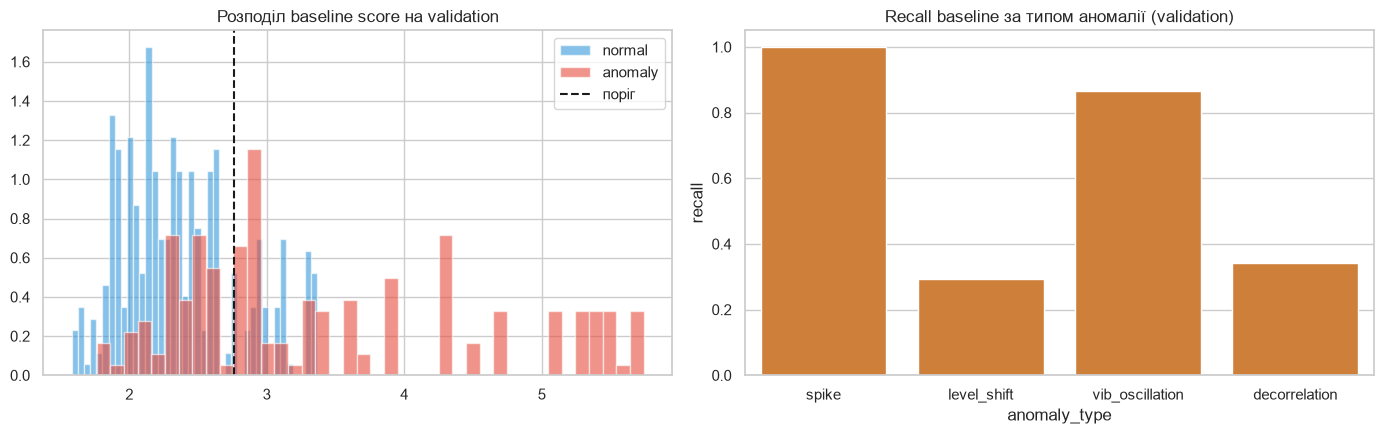

,anomaly_type,windows,recall
0,spike,37,1.000
1,level_shift,34,0.294
2,vib_oscillation,74,0.865
3,decorrelation,38,0.342


In [3]:
rbt = recall_by_type(yva, tva, s_va, th)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lab, c, n in [(0, "#3498db", "normal"), (1, "#e74c3c", "anomaly")]:
    axes[0].hist(s_va[yva == lab], bins=40, alpha=0.6, color=c, label=n, density=True)
axes[0].axvline(th, color="k", ls="--", label="поріг")
axes[0].set_title("Розподіл baseline score на validation"); axes[0].legend()
sns.barplot(data=rbt, x="anomaly_type", y="recall", ax=axes[1], color="#e67e22")
axes[1].set_ylim(0, 1.05); axes[1].set_title("Recall baseline за типом аномалії (validation)")
plt.tight_layout(); plt.show()
rbt.round(3)

**Спостереження:** baseline надійно ловить різкі викиди (`spike`), але погано бачить `level_shift` (зсув менший за поріг) і `decorrelation` (значення в нормі, порушений лише зв'язок між каналами). Це обґрунтовує спробу DL-моделі, що враховує форму сигналу та взаємозв'язок каналів.